In [1]:
import numpy as np
import scipy.io as sio
from pyproj import Transformer
import pandas as pd  
import matplotlib.pyplot as plt

In [2]:
datapath = '/private/var/phys-admin/Documents/Jakob/MC-SSA/data/'
path1 = f"{datapath}BedMap3-radar-thk-profiles/bedmap3_raw_data/UTIG_2010_ICECAP_AIR_BM3.csv"
path2 = f"{datapath}BedMap3-radar-thk-profiles/bedmap3_raw_data/NASA_2019_ICEBRIDGE_AIR_BM3.csv"
path3 = f"{datapath}BedMap3-radar-thk-profiles/bedmap3_raw_data/UTIG_2015_EAGLE_AIR_BM3.csv"
path4 = f"{datapath}BedMap3-radar-thk-profiles/bedmap2_raw_data/BAS_2005_WISE-ISODYN_AIR_BM2.csv"
path5 = f"{datapath}BedMap3-radar-thk-profiles/bedmap2_raw_data/NASA_2011_ICEBRIDGE_AIR_BM2.csv"

In [ ]:
datapath = # path to data
path1 = f"{datapath}bedmap3_raw_data/UTIG_2010_ICECAP_AIR_BM3.csv"
path2 = f"{datapath}bedmap3_raw_data/NASA_2019_ICEBRIDGE_AIR_BM3.csv"
path3 = f"{datapath}bedmap3_raw_data/UTIG_2015_EAGLE_AIR_BM3.csv"
path4 = f"{datapath}bedmap2_raw_data/BAS_2005_WISE-ISODYN_AIR_BM2.csv"
path5 = f"{datapath}bedmap2_raw_data/NASA_2011_ICEBRIDGE_AIR_BM2.csv"

In [3]:
ds1 = pd.read_csv(path1,delimiter=',',header=18)
ds2 = pd.read_csv(path2,delimiter=',',header=18)
ds3 = pd.read_csv(path3,delimiter=',',header=18)
ds4 = pd.read_csv(path4,delimiter=',',header=18)
ds5 = pd.read_csv(path5,delimiter=',',header=18)

In [4]:
ds1mask = np.where(ds1['land_ice_thickness (m)']>=0.)
ds2mask = np.where(ds2['land_ice_thickness (m)']>=0.)
ds3mask = np.where(ds3['land_ice_thickness (m)']>=0.)
ds4mask = np.where(ds4['land_ice_thickness (m)']>=0.)
ds5mask = np.where(ds5['land_ice_thickness (m)']>=0.)

In [5]:
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:3130",
    always_xy=True  # input order is (longitude, latitude)
)

In [6]:
x1,y1 = transformer.transform(ds1['longitude (degree_east)'],ds1['latitude (degree_north)'])
x2,y2 = transformer.transform(ds2['longitude (degree_east)'],ds2['latitude (degree_north)'])
x3,y3 = transformer.transform(ds3['longitude (degree_east)'],ds3['latitude (degree_north)'])
x4,y4 = transformer.transform(ds4['longitude (degree_east)'],ds4['latitude (degree_north)'])
x5,y5 = transformer.transform(ds5['longitude (degree_east)'],ds5['latitude (degree_north)'])

In [7]:
allthk = np.concatenate((
        ds1['land_ice_thickness (m)'][ds1mask[0]].to_numpy(),
        ds2['land_ice_thickness (m)'][ds2mask[0]].to_numpy(),
        ds3['land_ice_thickness (m)'][ds3mask[0]].to_numpy(),
        ds4['land_ice_thickness (m)'][ds4mask[0]].to_numpy(),
        ds5['land_ice_thickness (m)'][ds5mask[0]].to_numpy()
        ))

allx = np.concatenate((x1[ds1mask],x2[ds2mask],x3[ds3mask],x4[ds4mask],x5[ds5mask]))
ally = np.concatenate((y1[ds1mask],y2[ds2mask],y3[ds3mask],y4[ds4mask],y5[ds5mask]))

In [8]:
data = {"median-thickness": allthk, "x": allx, "y": ally}
sio.savemat(f"{datapath}Byrd-Cook-Denman-BM3-500m-median-thk.mat", data)

In [9]:
test = sio.loadmat(f"{datapath}Byrd-Cook-Denman-BM3-500m-median-thk.mat")

(-12000000.0, -9000000.0)

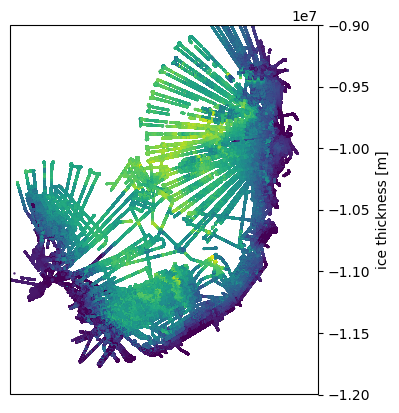

In [12]:
fig,ax = plt.subplots(1,1)
a=ax.scatter(test['x'],test['y'],c=test['median-thickness'],s=0.5)
cax=fig.colorbar(a,cax=ax)
cax.set_label('ice thickness [m]')
ax.set_aspect(1)
ax.set_xlim(1e6,3.5e6)
ax.set_ylim(-1.2e7,-0.9e7)